# VK Education Project: Стабилизация эмбеддингов

Автор: Перепелюк Иван Александрович

TG: @perepelyuk10

В примере сравниваются две версии эмбеддингов пользователей и объектов. Вторая версия получена поворотом первой на 75°. Проверим сохранение оценок рекомендаций и сходство версий после выравнивания.

Ноутбук импортирует необходимые модули из папки `stabilization`. 

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display

root = Path.cwd()
if not (root / "stabilization").is_dir():
    root = root.parent
if not (root / "stabilization").is_dir():
    raise RuntimeError("Откройте ноутбук из папки проекта или из notebooks.")
sys.path.insert(0, str(root))

from stabilization.method import align, fit_svd
from stabilization.metrics import mean_cosine, score_error
from stabilization.synthetic import SyntheticConfig, make_embeddings

torch.set_num_threads(1)

## Локальный расчёт

Сначала задаём эталонное пространство для версии 0. Затем рассчитываем преобразование версии 1 и выравниваем её по объектам версии 0. В генераторе одинаковый номер строки соответствует одному и тому же ID.

In [2]:
config = SyntheticConfig(users=256, items=192, dim=16, angle=75, seed=42)
users0, items0 = make_embeddings(config, version=0)
users1, items1 = make_embeddings(config, version=1)

reference = fit_svd(users0, items0)
ref_users, ref_items = reference.apply(users0, items0)
current = fit_svd(users1, items1)
aligned = align(current, items1, ref_items)
stable_users, stable_items = aligned.apply(users1, items1)

print(f"Пользователей: {len(users0)} | Объектов: {len(items0)}")
print(f"Размерность: {config.dim} | Численный ранг: {aligned.effective_rank}")

Пользователей: 256 | Объектов: 192
Размерность: 16 | Численный ранг: 16


## Численная проверка

Здесь матрица оценок достаточно мала для прямой проверки. В распределённом режиме метрика считается на выборке пар внутри блоков.

In [3]:
original_scores = items1 @ users1.T
stable_scores = stable_items @ stable_users.T
torch.testing.assert_close(stable_scores, original_scores, rtol=1e-11, atol=1e-11)

direct_singular = torch.linalg.svdvals(original_scores)[: config.dim]
torch.testing.assert_close(aligned.singular_values, direct_singular)

errors = score_error(users1, items1, stable_users, stable_items)
print(f"Относительная ошибка по выборке: {errors['relative_l2']:.2e}")
print(f"Максимальная ошибка по всей матрице: {(stable_scores - original_scores).abs().max():.2e}")

Относительная ошибка по выборке: 1.56e-15
Максимальная ошибка по всей матрице: 3.11e-14


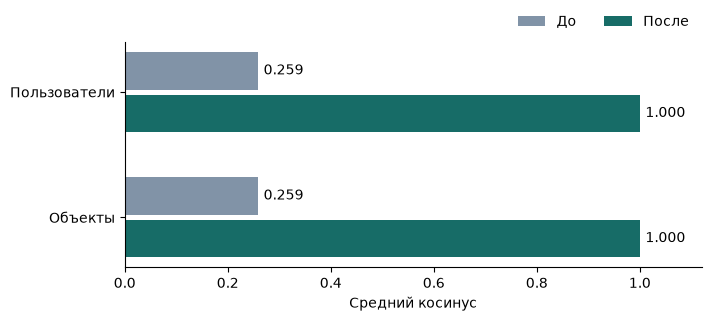

In [4]:
before = [
    mean_cosine(users0, users1)["mean"],
    mean_cosine(items0, items1)["mean"],
]
after = [
    mean_cosine(ref_users, stable_users)["mean"],
    mean_cosine(ref_items, stable_items)["mean"],
]
assert min(after) > 1 - 1e-12

fig, ax = plt.subplots(figsize=(7, 3.1), layout="constrained")
labels = ["Пользователи", "Объекты"]
positions = [0, 1]
bars_before = ax.barh([y - 0.17 for y in positions], before, 0.30, label="До", color="#8193a7")
bars_after = ax.barh([y + 0.17 for y in positions], after, 0.30, label="После", color="#176c67")
ax.set(yticks=positions, yticklabels=labels, xlim=(0, 1.12), xlabel="Средний косинус")
ax.bar_label(bars_before, fmt="%.3f", padding=4)
ax.bar_label(bars_after, fmt="%.3f", padding=4)
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncols=2, frameon=False)
plt.show()

## Результаты запусков проекта

Таблица строится из JSON в папке `results`. Сценарии с поворотом и шумом сравниваются по одним и тем же метрикам.

In [5]:
experiments = {
    "cpu-1": "Поворот",
    "cpu-2": "Поворот",
    "cpu-4": "Поворот",
    "cuda-1": "Поворот",
    "align-noise": "Поворот и шум",
}
rows = [
    "| Сценарий | Устройство | Процессы | Косинус пользователей | Косинус объектов | Ошибка оценок |",
    "| --- | --- | ---: | ---: | ---: | ---: |",
]
for filename, scenario in experiments.items():
    result = json.loads((root / "results" / f"{filename}.json").read_text(encoding="utf-8"))
    iteration = result["iteration"]
    cos = iteration["cosine"]
    rows.append(
        f"| {scenario} | {result['device'].upper()} | {result['processes']} "
        f"| {cos['users_before']['mean']:.4f} → {cos['users_after']['mean']:.4f} "
        f"| {cos['items_before']['mean']:.4f} → {cos['items_after']['mean']:.4f} "
        f"| {iteration['scores']['relative_l2']:.2e} |"
    )
display(Markdown("\n".join(rows)))

| Сценарий | Устройство | Процессы | Косинус пользователей | Косинус объектов | Ошибка оценок |
| --- | --- | ---: | ---: | ---: | ---: |
| Поворот | CPU | 1 | 0.2588 → 1.0000 | 0.2588 → 1.0000 | 2.15e-15 |
| Поворот | CPU | 2 | 0.2588 → 1.0000 | 0.2588 → 1.0000 | 2.29e-15 |
| Поворот | CPU | 4 | 0.2588 → 1.0000 | 0.2588 → 1.0000 | 2.19e-15 |
| Поворот | CUDA | 1 | 0.2588 → 1.0000 | 0.2588 → 1.0000 | 1.55e-15 |
| Поворот и шум | CPU | 2 | 0.2557 → 0.9889 | 0.2558 → 0.9890 | 2.30e-15 |

## Время расчёта на CPU

Для замера взяты 65 536 пользователей, 49 152 объекта и размерность 64. Показано время одного запуска на каждую конфигурацию. Замер включает оба QR и SVD. Запуск процессов и генерация данных в замер не входят.

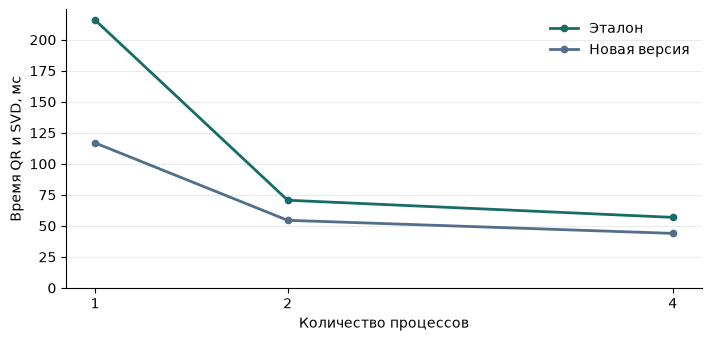

In [6]:
process_counts = [1, 2, 4]
timings = [
    json.loads((root / "results" / f"scale-cpu-{n}.json").read_text(encoding="utf-8"))
    for n in process_counts
]
fig, ax = plt.subplots(figsize=(7, 3.3), layout="constrained")
for stage, label, color in [
    ("reference", "Эталон", "#176c67"),
    ("iteration", "Новая версия", "#526e8b"),
]:
    times = [1000 * result[stage]["fit_seconds"] for result in timings]
    ax.plot(process_counts, times, ".-", color=color, linewidth=2, markersize=9, label=label)
ax.set(xticks=process_counts, xlabel="Количество процессов", ylabel="Время QR и SVD, мс", ylim=(0, None))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
plt.show()

## Повтор распределённого запуска

Поставьте `run_distributed = True` и выполните ячейку. Она запускает два процесса CPU через `torchrun` и сохраняет метрики в `runs/notebook-cpu-2.json`.

In [7]:
run_distributed = False

if run_distributed:
    output = Path("runs/notebook-cpu-2.json")
    command = [
        sys.executable, "-m", "stabilization.launch",
        "--processes", "2", "demo", "--output", str(output),
    ]
    process = subprocess.run(command, cwd=root, capture_output=True, text=True, timeout=120)
    if process.returncode:
        raise RuntimeError(process.stdout + process.stderr)
    metrics = json.loads((root / output).read_text(encoding="utf-8"))
    print(json.dumps(metrics["iteration"], indent=2))